# DESeq2 versus BN: host-specific bottleneck simulations

Current design: 100 variants; five inoculum samples and five recipient hosts; 10 datasets. Donor counts are multinomial with fixed uniform true frequencies. Group sizes are sampled uniformly over positive integer triples summing to K. Selection decreases depleted frequencies by fraction DELTA and distributes the removed mass equally among enriched variants; DELTA=0 means all variants are neutral. Each recipient follows multinomial founder sampling, Dirichlet growth on positive founders, and multinomial sequencing. Bottlenecks vary by scenario A–D.

The generating frequencies are independent of observed donor sampling error. BN still uses pooled observed donor counts, while DESeq2 uses the five control samples separately.

## Recover the run you already completed

**Do not Run All and do not rerun the expensive simulation/test cell.**

1. Run the code cell under **Comparison metrics**, defining `standardize_results()` and the corrected `evaluate()`.
2. Run the cell under **Summarize effectiveness**, beginning `# RECOVER SAVED RESULTS ONLY`. Set `RESULTS_DIR` to the existing folder containing `all_predictions.csv` (default: `deseq2_bn_comparison`). This cell imports its own packages and does not require R or the BN module.
3. Run **Plots**, and optionally the ZIP/download cells.

Recovery writes `metrics_per_dataset_recovered.csv` and preserves the original metrics CSV and prediction files. Missing old runtimes remain NaN; they are not recoverable from prediction labels. Old simulation outputs retained elsewhere in this notebook are historical, not newly executed results.

For a new experiment, run setup and Settings normally and use a new output folder. Before recovery/plotting that new run, point `RESULTS_DIR` to that same folder.


## Prerequisites

Install Python dependencies of the BN module, plus `numpy`, `pandas`, `matplotlib`, `scipy`, and Jupyter. The BN module's default backend needs its C++ compiler setup.

Install R and DESeq2 separately. In an R console, if needed:
```r
if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager")
BiocManager::install("DESeq2", ask=FALSE, update=FALSE)
```
Set `RSCRIPT` below to the executable's full path if it is not on PATH, for example `C:/Program Files/R/R-4.x.x/bin/Rscript.exe` on Windows. Package installation is not run automatically.

Reference: [official DESeq2 vignette](https://bioconductor.org/packages/release/bioc/vignettes/DESeq2/inst/doc/DESeq2.html).


In [1]:
%pip install -q rpy2
%load_ext rpy2.ipython

In [ ]:
%%R
if (!requireNamespace("BiocManager", quietly = TRUE)) {install.packages("BiocManager", repos = "https://cloud.r-project.org")}
BiocManager::install("DESeq2", ask = FALSE, update = FALSE)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/BiocManager_1.30.27.tar.gz'
Content type 'application/x-gzip' length 752490 bytes (734 KB)
downloaded 734 KB


The downloaded source packages are in
	‘/tmp/RtmpSsld4B/downloaded_packages’
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com
Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)
Installing package(s) 'BiocVersion', 'DESeq2'
also installing the dependencies ‘XVector’, ‘formatR’, ‘abind’, ‘SparseArray’, ‘lambda.r’, ‘futile.options’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘S4Vectors’, ‘IRanges’, ‘GenomicRanges’, ‘SummarizedExperiment’, ‘BiocGenerics’, ‘Biobase’, ‘BiocParallel’, ‘matrixStats’, ‘locfit’, ‘MatrixGenerics’, ‘RcppArmadillo’

trying URL 'https://bio

In [ ]:
%%R
library(DESeq2)
packageVersion("DESeq2")

[1] ‘1.52.0’


Loading required package: S4Vectors
Loading required package: stats4
Loading required package: BiocGenerics
Loading required package: generics

Attaching package: ‘generics’

The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union


Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min


Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following object

In [3]:
from pathlib import Path
import json
import shutil
import subprocess
import sys
import time
import hashlib
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import neutrality_test_bootstrap as bn_module
from neutrality_test_bootstrap import neutrality_bootstrap

## Generate counts and known truth

Donor samples are independent multinomial draws from the true uniform frequency vector D. Recipient founders are sampled using the selection-modified vector q, followed by neutral Dirichlet growth and sequencing. Neutral means q_j=D_j in expectation, not equality in each realized host. Zero-founder variants stay absent.


In [ ]:
def simulate_dataset(rng):
    ids = pd.Index([f"variant_{j+1:03d}" for j in range(K)], name="feature",)

    seeds = rng.integers(0, 2**32, size=3, dtype=np.uint64)
    donor_rng = np.random.default_rng(int(seeds[0]))
    label_rng = np.random.default_rng(int(seeds[1]))
    host_rng = np.random.default_rng(int(seeds[2]))

    # real donor frequency
    D = np.full(K, 1.0 / K)

    # 5 independent inoculum dataset.
    inoculum = pd.DataFrame(donor_rng.multinomial(DONOR_DEPTH, D, size=N_INOCULUM), index=[f"inoculum_{i+1}" for i in range(N_INOCULUM)], columns=ids,)
    pooled = inoculum.sum(axis=0).rename("pooled_inoculum")

    # Uniform over positive integer triples (n_depleted, n_enriched, n_neutral)
    # Independent discrete uniforms, including both endpoints.
    n_depleted = int(label_rng.integers(5, 16))
    n_enriched = int(label_rng.integers(5, 16))
    n_neutral = K - n_depleted - n_enriched

    # Random group membership, shared across scenarios when seeds match.
    order = label_rng.permutation(K)
    down = order[:n_depleted]
    up = order[n_depleted:n_depleted + n_enriched]

    q = D.copy()
    q[down] = (1.0 - DELTA) * D[down]
    # Redistribute exactly the depleted mass; neutral frequencies stay unchanged.
    removed_mass = DELTA * D[down].sum()
    q[up] = D[up] + removed_mass / n_enriched

    labels = np.full(K, "neutral", dtype=object)
    if DELTA > 0:
        labels[down] = "depleted"
        labels[up] = "enriched"

    assert np.isclose(q.sum(), 1.0)
    assert np.all(q > 0)

    # Founder -> neutral growth -> sequencing, riêng cho mỗi host.
    recipient_array = np.zeros((N_HOSTS, K), dtype=np.int64)

    for m, nb in enumerate(NB_BY_HOST):
        founders = host_rng.multinomial(int(nb), q)
        active = founders > 0

        host_frequency = np.zeros(K)
        host_frequency[active] = host_rng.dirichlet(founders[active].astype(float))

        recipient_array[m] = host_rng.multinomial(RECIPIENT_DEPTH, host_frequency)

    recipient = pd.DataFrame(recipient_array, index=[f"recipient_{i+1}" for i in range(N_HOSTS)], columns=ids,)

    truth = pd.DataFrame({"true_class": labels, "D_reference": D, "q_target": q, "true_log2FC": np.log2(q / D),}, index=ids,)

    counts = pd.concat([inoculum, recipient]).T
    metadata = pd.DataFrame({"condition":["inoculum"] * N_INOCULUM + ["recipient"] * N_HOSTS},index=counts.columns,)
    metadata.index.name = "sample"

    return inoculum, recipient, pooled, counts, metadata, truth

In [ ]:
def safe_ratio(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan

## R DESeq2 runner

This code is embedded in the notebook and written to an R script when the experiment starts. It receives only counts and group labels. It saves both the original DESeq2 results and BH values over all 100 variants used for the comparison. R warnings and session information are preserved.


In [ ]:
R_CODE = '\nsuppressPackageStartupMessages(library(DESeq2))\na <- commandArgs(trailingOnly=TRUE)\ncounts <- as.matrix(read.csv(a[1], row.names=1, check.names=FALSE))\nmetadata <- read.csv(a[2], row.names=1, check.names=FALSE)\noutdir <- a[3]\nalpha <- as.numeric(a[4])\nnormalization <- a[5]\nfit_type <- a[6]\nstopifnot(all(counts >= 0), all(counts == round(counts)))\nstorage.mode(counts) <- "integer"\nmetadata <- metadata[colnames(counts), , drop=FALSE]\nmetadata$condition <- factor(metadata$condition, levels=c("inoculum", "recipient"))\nstopifnot(identical(rownames(metadata), colnames(counts)))\ndds <- DESeqDataSetFromMatrix(countData=counts, colData=metadata, design=~condition)\nif (normalization == "total_count") {\n    totals <- colSums(counts)\n    sizeFactors(dds) <- totals / exp(mean(log(totals)))\n} else if (normalization != "median_ratio") {\n    stop("Unknown normalization")\n}\ndds <- DESeq(dds, test="Wald", fitType=fit_type, quiet=TRUE)\nres <- results(dds, contrast=c("condition", "recipient", "inoculum"),\n               alpha=alpha, lfcThreshold=0, independentFiltering=FALSE)\nout <- as.data.frame(res)\nout$feature <- rownames(out)\nout$p_missing <- !is.finite(out$pvalue)\np <- out$pvalue\np[!is.finite(p)] <- 1\nout$padj_all_K <- p.adjust(p, method="BH")\nout$reject_all_K <- out$padj_all_K <= alpha\nwrite.csv(out, file.path(outdir, "deseq2_results.csv"), row.names=FALSE)\nwrite.csv(data.frame(sample=colnames(dds), size_factor=sizeFactors(dds)),\n          file.path(outdir, "deseq2_size_factors.csv"), row.names=FALSE)\ncapture.output(sessionInfo(), file=file.path(outdir, "R_sessionInfo.txt"))\n'

def run_deseq2(folder, script_path):
    start = time.perf_counter()
    cmd = [r_executable, "--vanilla", str(script_path.resolve()), str((folder / "counts_for_DESeq2.csv").resolve()),
           str((folder / "sample_metadata.csv").resolve()), str(folder.resolve()), str(ALPHA), DESEQ_NORMALIZATION, DESEQ_FIT_TYPE]
    with (folder / "DESeq2.log").open("w", encoding="utf-8") as log:
        completed = subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT, text=True)
    if completed.returncode:
        raise RuntimeError(f"DESeq2 failed; see {folder / 'DESeq2.log'}. No dataset is silently skipped.")
    return pd.read_csv(folder / "deseq2_results.csv"), time.perf_counter() - start


## Comparison metrics

A true positive is a truly changed variant rejected by the method; direction is assessed separately. Sensitivity is $TP/(TP+FN)$, precision is $TP/(TP+FP)$, false-positive rate is $FP/(FP+TN)$, and the false-discovery proportion is $FP/\max(TP+FP,1)$. Precision is undefined (`NaN`) when nothing is detected; FDP is then zero. The average FDP across datasets is a simulation estimate of FDR, with substantial uncertainty from only 10 datasets.

Depletion and enrichment sensitivities count detections **in the correct direction**. All methods are evaluated against all 100 labels. Their failure to return a usable p-value is recorded and counts as a non-detection. No hard fold-change cutoff is applied.


In [5]:
def standardize_results(raw, method, truth):
    if not raw.feature.is_unique or set(raw.feature) != set(truth.index):
        raise ValueError(f"{method}: feature labels do not match truth.")
    r = raw.set_index("feature").reindex(truth.index)
    if method == "BN":
        p = r.pval.to_numpy(float)
        adjusted = r.qval_FDR.to_numpy(float)
        sign = r.direction.map({"down_in_recipient": -1, "up_in_recipient": 1,
                                "unchanged": 0}).fillna(0).to_numpy()
        missing = ~np.isfinite(p) | ~np.isfinite(adjusted)
    else:
        p = r.pvalue.to_numpy(float)
        adjusted = r.padj_all_K.to_numpy(float)
        sign = np.sign(r.log2FoldChange.to_numpy(float))
        missing = ~np.isfinite(p) | ~np.isfinite(adjusted) | ~np.isfinite(sign)
    rejected = (adjusted <= ALPHA) & ~missing
    predicted = np.full(K, "not_detected", dtype=object)
    predicted[rejected & (sign < 0)] = "depleted"
    predicted[rejected & (sign > 0)] = "enriched"
    if np.any(rejected & ((sign == 0) | ~np.isfinite(sign))):
        raise ValueError(f"{method}: significant variant without a valid direction.")
    return truth.assign(method=method, pvalue=p, adjusted_pvalue=adjusted,
                        rejected=rejected, predicted_class=predicted, p_missing=missing)


def evaluate(frame, elapsed=np.nan):
    # Local safe division: this function is also usable during result recovery.
    def ratio(a, b):
        return float(a / b) if b > 0 else np.nan

    actual = frame.true_class.to_numpy()
    predicted = frame.predicted_class.to_numpy()
    if not np.isin(actual, ["neutral", "depleted", "enriched"]).all():
        raise ValueError("Unexpected truth label.")
    if not np.isin(predicted, ["not_detected", "depleted", "enriched"]).all():
        raise ValueError("Unexpected prediction label.")
    # Avoid unsafe conversion of CSV strings such as 'False' to bool.
    reject = predicted != "not_detected"
    if "rejected" in frame:
        reported = frame.rejected.astype(str).str.lower().map({"true": True, "false": False, "1": True, "0": False})
        if reported.isna().any() or not np.array_equal(reported.to_numpy(bool), reject):
            raise ValueError("Rejected flags and predicted classes disagree.")
    selected = actual != "neutral"
    tp = int((selected & reject).sum())
    fp = int((~selected & reject).sum())
    fn = int((selected & ~reject).sum())
    tn = int((~selected & ~reject).sum())
    n = len(frame)
    if n == 0:
        raise ValueError("Empty prediction group.")
    direction_ok = selected & (actual == predicted)
    n_detected = tp + fp
    missing_p = (int((~np.isfinite(pd.to_numeric(frame.pvalue, errors="coerce"))).sum())
                 if "pvalue" in frame else np.nan)
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, n_variants=n,
        n_true_depleted=int((actual == "depleted").sum()),
        n_true_enriched=int((actual == "enriched").sum()),
        n_true_neutral=int((actual == "neutral").sum()),
        n_detected=n_detected,
        detected_pool_percent=100*n_detected/n,
        depleted_pool_percent=100*np.mean(predicted == "depleted"),
        enriched_pool_percent=100*np.mean(predicted == "enriched"),
        sensitivity=ratio(tp, tp+fn), precision=ratio(tp, n_detected),
        FDP=fp/max(n_detected, 1), FPR=ratio(fp, fp+tn),
        specificity=ratio(tn, fp+tn), F1=ratio(2*tp, 2*tp+fp+fn),
        accuracy=(tp+tn)/n,
        directional_sensitivity=ratio(direction_ok.sum(), selected.sum()),
        depletion_sensitivity=ratio(np.sum((actual == "depleted") & (predicted == "depleted")), np.sum(actual == "depleted")),
        enrichment_sensitivity=ratio(np.sum((actual == "enriched") & (predicted == "enriched")), np.sum(actual == "enriched")),
        wrong_direction=int((selected & reject & (actual != predicted)).sum()),
        missing_pvalues=missing_p, elapsed_seconds=elapsed,)

## Settings

The current scenario determines one true bottleneck per host. Each dataset samples uniformly from all positive integer triples (n_depleted, n_enriched, n_neutral) summing to K. The three counts are dependent and their individual marginal distributions are not uniform. Depletion retains multiplier 1-DELTA; enrichment uses multiplier 1+DELTA*n_depleted/n_enriched, preserving total frequency and unchanged neutral frequencies. At DELTA=0 all truth labels are neutral. The test settings are preserved, including R=300: the minimum bootstrap p-value is 1/301 and BH at 0.05 over 100 variants requires at least 7 rejections for a nonempty rejection set.

DESeq2 uses sample-total normalization by default; median-ratio remains selectable. BH decisions use all variants; independent filtering is disabled, while Cook's-distance filtering remains enabled. BN estimates bottlenecks and refits them during bootstrap. True bottlenecks are used only by the simulator.


In [ ]:
rm -rf /content/comparison_C_delta_0.8/

In [ ]:
SCENARIOS = {
    "A": [400, 400, 400, 400, 400],
    "B": [4000, 6000, 5500, 4500, 6500],
    "C": [200, 200, 5000, 5000, 5000]*3,
    "D": [4800, 5000, 4500, 6000, 4000],
}

SCENARIO = "C"       # can change to A, B or C
DELTA = 0.8          # try with 0.0, 0.2, 0.5, 0.8; 0.0 = no selection.
NB_BY_HOST = np.asarray(SCENARIOS[SCENARIO], dtype=int)

K = 100
N_HOSTS = len(NB_BY_HOST)
N_INOCULUM = 5
N_DATASETS = 10
DONOR_DEPTH = 100_000
RECIPIENT_DEPTH = 100_000
GROUP_COUNT_SAMPLING = "independent_uniform_5_to_15_depleted_enriched"
OUTPUT = Path(f"comparison_{SCENARIO}_delta_{DELTA:g}")

assert len(NB_BY_HOST) == N_HOSTS
assert np.all(NB_BY_HOST > 0)
assert 0 <= DELTA < 1
assert K >= 3  # At least one variant in each group when DELTA > 0.
assert DONOR_DEPTH > 0

N_BOOT = 300
N_JOBS = 2
ALPHA = 0.05
SEED = 12345
DESEQ_NORMALIZATION = "total_count"  # Or "median_ratio" (standard DESeq2).
DESEQ_FIT_TYPE = "parametric"        # DESeq2 default; its warnings are logged.
RSCRIPT = "Rscript"                  # Or the full path to Rscript.exe.


assert N_DATASETS >= 2 and N_INOCULUM >= 2 and N_HOSTS >= 2
assert RECIPIENT_DEPTH > 0 and N_BOOT > 0 and 0 < ALPHA < 1
assert DESEQ_NORMALIZATION in {"total_count", "median_ratio"}

r_executable = shutil.which(RSCRIPT)
if r_executable is None:
    raise FileNotFoundError("Rscript was not found. Install R or set RSCRIPT to its full path.")
probe = subprocess.run([r_executable, "--vanilla", "-e",
    'if (!requireNamespace("DESeq2", quietly=TRUE)) stop("Install Bioconductor DESeq2 first"); cat(as.character(packageVersion("DESeq2")))'],
    capture_output=True, text=True)
if probe.returncode:
    raise RuntimeError(probe.stdout + "\n" + probe.stderr)
print("DESeq2 version:", probe.stdout.strip())
print("BN module:", bn_module.__file__)


DESeq2 version: 1.52.0
BN module: /content/neutrality_test_bootstrap.py


## Run the 10 datasets

This is the expensive cell. Inputs and truth are saved first; both methods analyze the same dataset. Results are checkpointed after each completed method. An error stops the run rather than silently removing an unsuccessful dataset. Use a new output directory to rerun.


In [ ]:
OUTPUT.mkdir(parents=True, exist_ok=False)
config = {name: globals()[name] for name in ["N_DATASETS", "K", "N_INOCULUM", "N_HOSTS",
    "RECIPIENT_DEPTH", "N_BOOT", "N_JOBS", "ALPHA", "SEED", "DESEQ_NORMALIZATION", "DESEQ_FIT_TYPE"]}
config["BN_module_sha256"] = hashlib.sha256(Path(bn_module.__file__).read_bytes()).hexdigest()
config["python_version"] = sys.version
config["packages"] = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]}
config.update(
    scenario=SCENARIO,
    delta=DELTA,
    Nb_by_host=NB_BY_HOST.tolist(),
    donor_depth=DONOR_DEPTH,
    group_count_sampling=GROUP_COUNT_SAMPLING,
    donor_generator="multinomial_fixed_uniform_frequency",)
(OUTPUT / "configuration.json").write_text(json.dumps(config, indent=2))
script_path = OUTPUT / "run_deseq2.R"
script_path.write_text(R_CODE)
streams = np.random.SeedSequence(SEED).spawn(N_DATASETS)
metrics_rows, prediction_frames, bottleneck_rows = [], [], []

for dataset in range(1, N_DATASETS + 1):
    sim_seed, bootstrap_stream = streams[dataset-1].spawn(2)
    test_seed = int(bootstrap_stream.generate_state(1)[0])
    folder = OUTPUT / f"dataset_{dataset:02d}"
    folder.mkdir()
    inoculum, recipient, pooled, counts, metadata, truth = simulate_dataset(np.random.default_rng(sim_seed))
    inoculum.to_csv(folder / "inoculum_counts.csv")
    recipient.to_csv(folder / "recipient_counts.csv")
    pooled.to_csv(folder / "pooled_inoculum.csv")
    counts.to_csv(folder / "counts_for_DESeq2.csv")
    metadata.to_csv(folder / "sample_metadata.csv")
    truth.to_csv(folder / "truth.csv")
    (folder / "bootstrap_seed.txt").write_text(str(test_seed))
    print(f"Dataset {dataset}/{N_DATASETS}: {truth.true_class.value_counts().to_dict()}", flush=True)

    print("  Running DESeq2...", flush=True)
    raw_de, de_seconds = run_deseq2(folder, script_path)
    de_frame = standardize_results(raw_de, "DESeq2", truth).assign(dataset=dataset)
    de_frame.to_csv(folder / "DESeq2_predictions_with_truth.csv")
    metrics_rows.append(dict(dataset=dataset, method="DESeq2", **evaluate(de_frame, de_seconds)))
    prediction_frames.append(de_frame.reset_index())
    pd.DataFrame(metrics_rows).to_csv(OUTPUT / "metrics_per_dataset.csv", index=False)
    pd.concat(prediction_frames, ignore_index=True).to_csv(OUTPUT / "all_predictions.csv", index=False)

    print("Running BN bootstrap...", flush=True)
    start = time.perf_counter()
    raw_bn, diagnostics = neutrality_bootstrap(
        pooled, recipient, reestimate_bottleneck=True, n_boot=N_BOOT,
        n_jobs=N_JOBS, seed=test_seed, fdr_alpha=ALPHA, fdr_method="fdr_bh",
        pseudocount=0.0, progress_every=50)
    bn_seconds = time.perf_counter() - start
    raw_bn.to_csv(folder/"BN_results.csv", index=False)
    diagnostics["observed_bottlenecks"].to_csv(folder/"BN_observed_bottlenecks.csv")
    diagnostics["bootstrap_bottlenecks"].to_csv(folder/"BN_bootstrap_bottlenecks.csv", index=False)
    for host, estimate in diagnostics["observed_bottlenecks"].items():
        bottleneck_rows.append(dict(dataset=dataset, host=host, estimated_Nb=estimate))
    bn_frame = standardize_results(raw_bn, "BN", truth).assign(dataset=dataset)
    bn_frame.to_csv(folder / "BN_predictions_with_truth.csv")
    metrics_rows.append(dict(dataset=dataset, method="BN", **evaluate(bn_frame, bn_seconds)))
    prediction_frames.append(bn_frame.reset_index())
    pd.DataFrame(metrics_rows).to_csv(OUTPUT / "metrics_per_dataset.csv", index=False)
    pd.concat(prediction_frames, ignore_index=True).to_csv(OUTPUT / "all_predictions.csv", index=False)
    pd.DataFrame(bottleneck_rows).to_csv(OUTPUT / "BN_bottleneck_estimates.csv", index=False)
    print("Completed and saved.", flush=True)


Dataset 1/10: {'neutral': 90, 'enriched': 5, 'depleted': 5}
  Running DESeq2...
Running BN bootstrap...
Fitting observed bottlenecks and computing observed statistics...
Bootstrap 1/300; elapsed 7.6 s
Bootstrap 50/300; elapsed 120.9 s
Bootstrap 100/300; elapsed 240.2 s
Bootstrap 150/300; elapsed 358.7 s
Bootstrap 200/300; elapsed 477.5 s
Bootstrap 250/300; elapsed 595.4 s
Bootstrap 300/300; elapsed 714.3 s
Completed and saved.
Dataset 2/10: {'neutral': 77, 'depleted': 14, 'enriched': 9}
  Running DESeq2...
Running BN bootstrap...
Fitting observed bottlenecks and computing observed statistics...
Bootstrap 1/300; elapsed 6.1 s
Bootstrap 50/300; elapsed 118.5 s
Bootstrap 100/300; elapsed 235.6 s
Bootstrap 150/300; elapsed 353.0 s
Bootstrap 200/300; elapsed 470.6 s
Bootstrap 250/300; elapsed 587.6 s
Bootstrap 300/300; elapsed 704.1 s
Completed and saved.
Dataset 3/10: {'neutral': 75, 'enriched': 13, 'depleted': 12}
  Running DESeq2...
Running BN bootstrap...
Fitting observed bottlenecks an

## Summarize effectiveness

Means and standard deviations are across datasets, not across variants. Metrics are not pooled across datasets before averaging. The number of defined precision values is reported because precision is undefined for runs with no detections. Paired differences compare the methods on the same dataset. No significance claim is inferred from these 10 replicates alone.


In [ ]:
matches = sorted(Path("/content").rglob("all_predictions.csv"))

if not matches:
    print("not found all_predictions.csv in /content.")
else:
    for path in matches:
        print(f'RESULTS_DIR = Path("{path.parent}")')

RESULTS_DIR = Path("/content/comparison_C_delta_0.8")


In [19]:
# RECOVER SAVED RESULTS ONLY -- no simulation, R, or bootstrap calls.
RESULTS_DIR = Path("/content/comparison_C_delta_0.8") # For a future run, set e.g. Path("comparison_C_delta_0.5").
OUTPUT = RESULTS_DIR  # Summary/plots are written beside the recovered results.

prediction_path = OUTPUT / "all_predictions.csv"
if not prediction_path.exists():
    raise FileNotFoundError(f"Set RESULTS_DIR to the folder containing all_predictions.csv: {OUTPUT.resolve()}")
predictions = pd.read_csv(prediction_path)
required = {"dataset", "method", "feature", "true_class", "predicted_class"}
if not required.issubset(predictions):
    raise ValueError(f"Missing prediction columns: {required - set(predictions.columns)}")
if predictions.duplicated(["dataset", "method", "feature"]).any():
    raise ValueError("Duplicate dataset/method/feature rows.")
if set(predictions.method) != {"DESeq2", "BN"}:
    raise ValueError("Need saved predictions from both methods.")
for dataset, group in predictions.groupby("dataset"):
    de = group.loc[group.method == "DESeq2"].set_index("feature").true_class.sort_index()
    bn = group.loc[group.method == "BN"].set_index("feature").true_class.sort_index()
    if not de.equals(bn):
        raise ValueError(f"Dataset {dataset}: methods have different features or truth labels.")
config_path = OUTPUT / "configuration.json"
saved_config = json.loads(config_path.read_text()) if config_path.exists() else {}
K = int(saved_config.get("K", predictions.groupby(["dataset", "method"]).size().iloc[0]))
N_DATASETS = int(saved_config.get("N_DATASETS", predictions.dataset.nunique()))
ALPHA = float(saved_config.get("ALPHA", 0.05))
DESEQ_NORMALIZATION = saved_config.get("DESEQ_NORMALIZATION", "not recorded")
sizes = predictions.groupby(["dataset", "method"]).size()
if not sizes.eq(K).all() or len(sizes) != 2*N_DATASETS:
    raise ValueError("Saved predictions are incomplete for the configured dataset/variant counts.")

# Preserve recorded timings if available; never fabricate missing runtimes.
timing = {}
old_path = OUTPUT / "metrics_per_dataset.csv"
if old_path.exists():
    old = pd.read_csv(old_path)
    if {"dataset", "method", "elapsed_seconds"}.issubset(old.columns):
        if old.duplicated(["dataset", "method"]).any():
            raise ValueError("Duplicate timing records.")
        timing = old.set_index(["dataset", "method"])["elapsed_seconds"].to_dict()
rows = []
for (dataset, method), frame in predictions.groupby(["dataset", "method"], sort=False):
    rows.append(dict(dataset=dataset, method=method,
                     **evaluate(frame, timing.get((dataset, method), np.nan))))
metrics = pd.DataFrame(rows)
metrics.to_csv(OUTPUT / "metrics_per_dataset_recovered.csv", index=False)
if metrics.elapsed_seconds.isna().any():
    print("Missing runtimes are NaN; they cannot be reconstructed from predictions.")
print(f"Recovered metrics for {N_DATASETS} datasets, both methods. No tests rerun.")

metric_names = ["sensitivity", "precision", "FDP", "FPR", "F1", "accuracy",
                "depletion_sensitivity", "enrichment_sensitivity",
                "directional_sensitivity", "detected_pool_percent"]
if metrics["elapsed_seconds"].notna().any():
    metric_names.append("elapsed_seconds")
long = metrics.melt(id_vars=["dataset", "method"], value_vars=metric_names,
                    var_name="metric", value_name="value")
summary = long.groupby(["method", "metric"], sort=False).value.agg(
    n_defined="count", mean="mean", sd="std", median="median", minimum="min", maximum="max").reset_index()
summary.to_csv(OUTPUT / "summary_metrics.csv", index=False)
display(summary.round(4))
paired_rows = []
for metric in metric_names:
    wide = metrics.pivot(index="dataset", columns="method", values=metric)
    difference = wide["BN"] - wide["DESeq2"]
    paired_rows.append(dict(metric=metric, n_defined=int(difference.count()),
                            mean_BN_minus_DESeq2=difference.mean(), sd=difference.std()))
paired = pd.DataFrame(paired_rows)
paired.to_csv(OUTPUT / "paired_differences.csv", index=False)
display(paired.round(4))


Recovered metrics for 10 datasets, both methods. No tests rerun.


,method,metric,n_defined,mean,sd,median,minimum,maximum
0,DESeq2,sensitivity,10,0.1059,0.1313,0.0500,0.0000,0.3478
1,BN,sensitivity,10,0.9875,0.0395,1.0000,0.8750,1.0000
2,DESeq2,precision,5,1.0000,0.0000,1.0000,1.0000,1.0000
3,BN,precision,10,1.0000,0.0000,1.0000,1.0000,1.0000
4,DESeq2,FDP,10,0.0000,0.0000,0.0000,0.0000,0.0000
5,BN,FDP,10,0.0000,0.0000,0.0000,0.0000,0.0000
6,DESeq2,FPR,10,0.0000,0.0000,0.0000,0.0000,0.0000
7,BN,FPR,10,0.0000,0.0000,0.0000,0.0000,0.0000
8,DESeq2,F1,10,0.1700,0.2024,0.0909,0.0000,0.5161
9,BN,F1,10,0.9933,0.0211,1.0000,0.9333,1.0000


,metric,n_defined,mean_BN_minus_DESeq2,sd
0,sensitivity,10,0.8816,0.1259
1,precision,5,0.0000,0.0000
2,FDP,10,0.0000,0.0000
3,FPR,10,0.0000,0.0000
4,F1,10,0.8233,0.1972
5,accuracy,10,0.1710,0.0431
6,depletion_sensitivity,10,1.0000,0.0000
7,enrichment_sensitivity,10,0.7460,0.3002
8,directional_sensitivity,10,0.8816,0.1259
9,detected_pool_percent,10,17.1000,4.3063


## Plots

Points correspond to datasets; connecting lines pair the methods on the same data. Diamonds and bars show means and standard deviations, not confidence intervals. Pool percentages include a truth column. Confusion matrices use all 10 datasets and distinguish no detection from a true neutral label.


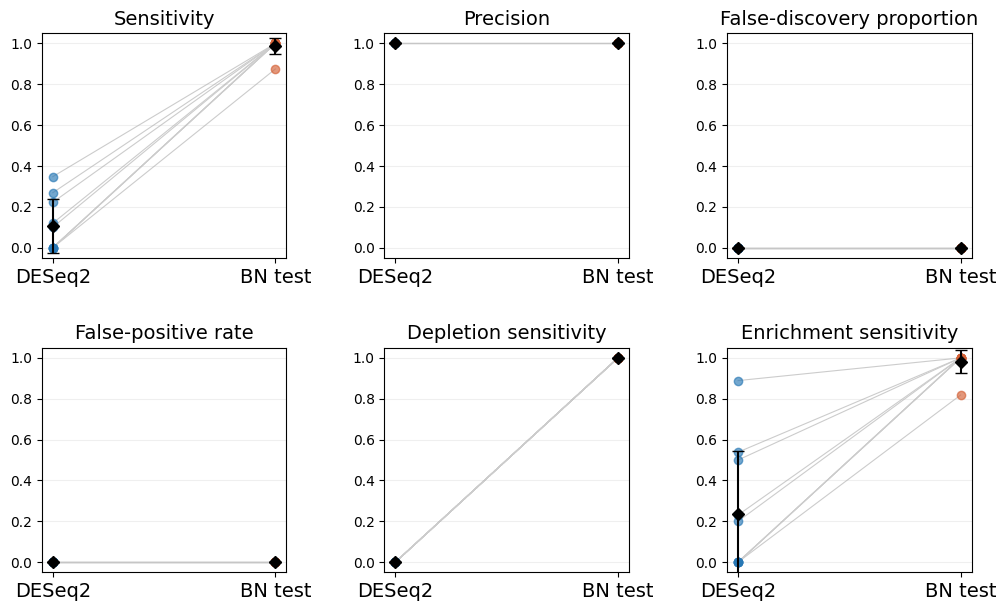

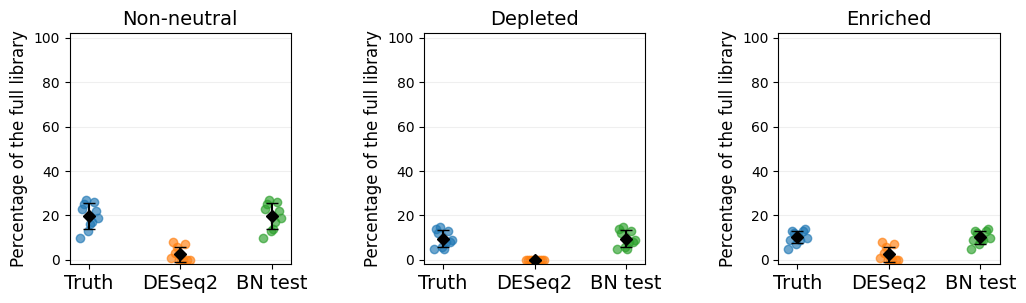

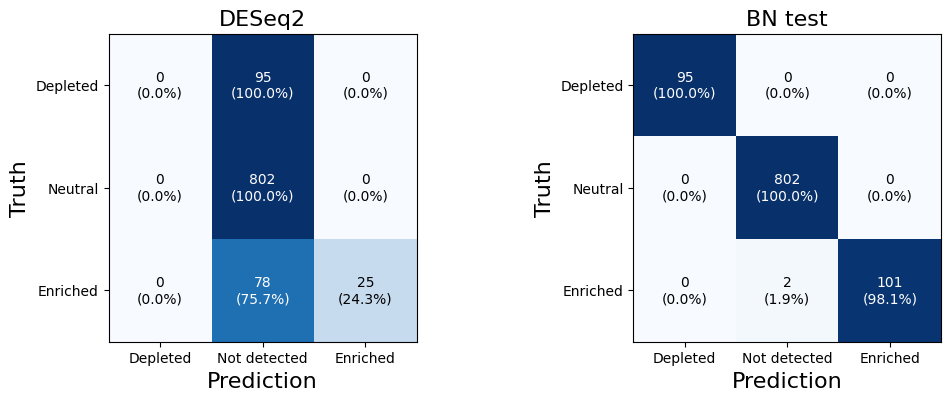

Saved outputs to /content/comparison_C_delta_0.8


In [22]:
methods = ["DESeq2", "BN"]
method_labels = ["DESeq2", "BN test"]
colors = ["#2878B5", "#D46035"]
def finish(fig, name):
    display(fig)
    plt.close(fig)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
plt.subplots_adjust(wspace = 0.4, hspace = 0.4)

for ax, metric, title in zip(axes.flat,
    ["sensitivity", "precision", "FDP", "FPR", "depletion_sensitivity", "enrichment_sensitivity"],
    ["Sensitivity", "Precision", "False-discovery proportion", "False-positive rate",
     "Depletion sensitivity", "Enrichment sensitivity"]):
    wide = metrics.pivot(index="dataset", columns="method", values=metric).reindex(columns=methods)
    for _, row in wide.iterrows():
        ax.plot([0, 1], row.to_numpy(float), color="0.8", linewidth=0.8, zorder=1)
    for x, method in enumerate(methods):
        values = wide[method].dropna().to_numpy()
        ax.scatter(np.full(len(values), x), values, color=colors[x], alpha=0.65, zorder=2)
        if len(values):
            ax.errorbar(x, values.mean(), yerr=values.std(ddof=1) if len(values)>1 else 0,
                        fmt="D", color="black", capsize=4, zorder=3)
    ax.set_xticks([0, 1], method_labels, fontsize = 14)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title, fontsize = 14)
    ax.grid(axis="y", alpha=0.2)
#fig.suptitle(f"Paired comparison: BH at {ALPHA}; DESeq2 normalization={DESEQ_NORMALIZATION}")
finish(fig, "method_effectiveness")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
plt.subplots_adjust(wspace = 0.6)
truth_counts = metrics.loc[metrics.method == "BN"].set_index("dataset")
for ax, category, column in zip(axes, ["Non-neutral", "Depleted", "Enriched"],
                               ["detected_pool_percent", "depleted_pool_percent", "enriched_pool_percent"]):
    actual = (100*(truth_counts.n_true_depleted + truth_counts.n_true_enriched)/K if category == "Non-neutral"
              else 100*truth_counts["n_true_depleted" if category == "Depleted" else "n_true_enriched"]/K)
    values_by_group = [actual.to_numpy()] + [metrics.loc[metrics.method == m, column].to_numpy() for m in methods]
    for x, values in enumerate(values_by_group):
        ax.scatter(x + np.linspace(-0.10, 0.10, len(values)), values, alpha=0.65)
        ax.errorbar(x, values.mean(), yerr=values.std(ddof=1), fmt="D", color="black", capsize=4)
    ax.set_xticks([0, 1, 2], ["Truth"] + method_labels, fontsize = 14)
    ax.set_title(category, fontsize = 14)
    ax.set_ylabel("Percentage of the full library", fontsize = 12)
    ax.set_ylim(-2, 102)
    ax.grid(axis="y", alpha=0.2)
finish(fig, "detected_pool_percentages")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plt.subplots_adjust(wspace = 0.6)
for ax, method in zip(axes, methods):
    frame = predictions.loc[predictions.method == method]
    cm = pd.crosstab(frame.true_class, frame.predicted_class).reindex(
        index=["depleted", "neutral", "enriched"], columns=["depleted", "not_detected", "enriched"], fill_value=0)
    cm.to_csv(OUTPUT / f"{method}_confusion_counts.csv")
    pct = 100 * cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0)
    pct.to_csv(OUTPUT / f"{method}_confusion_row_percentages.csv")
    ax.imshow(pct.to_numpy(), vmin=0, vmax=100, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm.iloc[i,j]}\n(" + (f"{pct.iloc[i,j]:.1f}%" if np.isfinite(pct.iloc[i,j]) else "N/A") + ")", ha="center", va="center",
                    color="white" if pct.iloc[i,j]>60 else "black")
    ax.set_xticks(range(3), ["Depleted", "Not detected", "Enriched"])
    ax.set_yticks(range(3), ["Depleted", "Neutral", "Enriched"])
    ax.set_xlabel("Prediction", fontsize = 16)
    ax.set_ylabel("Truth", fontsize = 16)
    ax.set_title("BN test" if method == "BN" else method, fontsize = 16)
finish(fig, "confusion_matrices")
print(f"Saved outputs to {OUTPUT.resolve()}")


In [ ]:
import shutil
archive_path = shutil.make_archive(str(OUTPUT.resolve()) + "_results", "zip", root_dir=OUTPUT)
print(archive_path)

/content/comparison_C_delta_0.8_results.zip


In [ ]:
from google.colab import files
files.download(archive_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Interpretation limits

- This benchmark is generated from the founder-mixture family used by BN. It cannot establish universal superiority over DESeq2.
- Both methods receive observed counts only. BN conditions on pooled donor frequencies; DESeq2 uses the five inoculum samples to estimate control variability.
- Selection acts through q before founder sampling. Estimated bottlenecks may differ from the true per-host values because of selection, sampling noise and estimation error.
- Report normalization, finite-bootstrap resolution and all scenarios, including DELTA=0. Zero detections remain in the analysis.
- Precision is undefined when nothing is detected; sensitivity is undefined when there are no truly changed variants. Missing quantities are reported as NaN/N/A, not zero.
- The mean FDP over datasets estimates FDR for this simulation setting; ten datasets provide limited precision. Inspect sensitivity alongside false discoveries.
